In [4]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2




r_seed = 42

WORKDIR = 'C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

C:\Users\cristiano.nascimento\AppData\Local\Temp\ipykernel_41484\847897453.py:15: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch
c:\Users\cristiano.nascimento\git\LSTM_giroscopio_acelerometro\.venv\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


In [5]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2




r_seed = 42

WORKDIR = 'C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

In [6]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [7]:
## get dataset
pd.set_option("display.precision", 9)

# select only sensor data from smart watches
data = pd.read_csv(WORKDIR+'/Code/DataPrep/concatenated_data_forth_trace.csv',dtype={"value": "float64"})

In [8]:
data.head()

,subject_id,device_id,accelerometer_x,accelerometer_y,accelerometer_z,gyroscope_x,gyroscope_y,gyroscope_z,magnetometer_x,magnetometer_y,magnetometer_z,timestamp,activity_label
0,0,1,-1.8650,9.3890,2.5812,-1.14180,-1.18560,0.84998,-0.34476,0.59839,1.0134,505.89,1
1,0,1,-1.7963,9.3742,2.4460,-1.56180,-0.66165,0.59730,-0.34274,0.57631,1.0000,525.42,1
2,0,1,-1.8696,9.3000,2.3514,-1.18770,-1.28410,0.14212,-0.34476,0.59639,1.0156,544.95,1
3,0,1,-1.7961,9.3624,2.4584,-0.58399,-2.03340,0.42912,-0.32863,0.62249,1.0156,564.48,1
4,0,1,-1.6768,9.3506,2.4685,-0.37050,-1.36470,0.37194,-0.33669,0.62048,1.0245,584.01,1


In [9]:
data.isnull().sum()

subject_id         0
device_id          0
accelerometer_x    0
accelerometer_y    0
accelerometer_z    0
gyroscope_x        0
gyroscope_y        0
gyroscope_z        0
magnetometer_x     0
magnetometer_y     0
magnetometer_z     0
timestamp          0
activity_label     0
dtype: int64

In [10]:
final_columns = [
        "pessoa_x",
        "id_dispositivo",
        "acelerômetro_x",
        "acelerômetro_Y",
        "acelerômetro_Z",
        "giroscópio_x",
        "giroscópio_Y",
        "giroscópio_Z",
        "magnetrômetro_x",
        "magnetrômetro_y",
        "magnetrômetro_z",
        "timestamp",
        "atividade"
    ]

In [11]:
data.columns = final_columns

In [12]:
""" ocurrences = ocurrence_unique_values(targets_data)
print(ocurrences) """

' ocurrences = ocurrence_unique_values(targets_data)\nprint(ocurrences) '

In [13]:
#print(grouped_data[0][1][0])

In [14]:
import numpy as np

# Example array with binary class indications, replace this with your actual array
#array_data = np.random.randint(0, 2, (4027, 7)).astype(float)  # Example data; replace with your own

def count_active_classes(array_data):
    # Sum across each row to get the number of classes present in each row
    active_classes_per_row = np.sum(array_data, axis=1)
    
    # Count unique values in active_classes_per_row to get how many rows have each class count
    unique_counts, count_of_rows = np.unique(active_classes_per_row, return_counts=True)
    
    # Map each unique count of active classes to the number of rows with that count
    count_summary = dict(zip(unique_counts.astype(int), count_of_rows))
    
    return count_summary

# Get the count of active classes for each row
#active_classes_count = count_active_classes(array_data)

# Print the results
""" for active_class_count, row_count in active_classes_count.items():
    print(f"Number of rows with {active_class_count} active classes: {row_count}") """


' for active_class_count, row_count in active_classes_count.items():\n    print(f"Number of rows with {active_class_count} active classes: {row_count}") '

In [15]:
""" ocurrences = ocurrence_unique_values(targets_data)
print(ocurrences) """

' ocurrences = ocurrence_unique_values(targets_data)\nprint(ocurrences) '

In [16]:
""" ocurrences = ocurrence_unique_values(targets_data)
print(ocurrences) """

' ocurrences = ocurrence_unique_values(targets_data)\nprint(ocurrences) '

In [17]:
import numpy as np
import random

def split_and_shuffle_3d_arrays(variable_data, labels_data, subjects_range):
    # Initialize lists for transition windows
    transition_windows_1 = []
    transition_windows_2 = []
    transition_windows_3 = []

    # Function to create transition windows for given class pairs
    def create_transition_windows(data, labels, class_a, class_b, transition_label, exclude_indices):
        transition_windows = []

        # Select unique class windows
        windows_class_a = [(i, w) for i, (w, l) in enumerate(zip(data, labels)) if np.unique(l) == class_a and i not in exclude_indices]
        windows_class_b = [(i, w) for i, (w, l) in enumerate(zip(data, labels)) if np.unique(l) == class_b and i not in exclude_indices]
        
        print(f"imprimindo comprimento windows_class_a: {len(windows_class_a)}")
        print(f"imprimindo comprimento windows_class_b: {len(windows_class_b)}")

        # Randomly select one third of each window type
        selected_windows_class_a = random.sample(windows_class_a, len(windows_class_a) // 3)
        selected_windows_class_b = random.sample(windows_class_b, len(windows_class_b) // 3)
        
        # Track excluded indices to avoid reuse in other transitions
        exclude_indices.update([i for i, _ in selected_windows_class_a])
        exclude_indices.update([i for i, _ in selected_windows_class_b])

        # Create pairs and transition windows
        for (_, w_a), (_, w_b) in zip(selected_windows_class_a, selected_windows_class_b):
            # Sophisticated transition window using linear interpolation
            transition_window = np.zeros_like(w_a)
            for t in range(200):
                alpha = t / 199  # Smoothly varies from 0 to 1
                transition_window[t] = (1 - alpha) * w_a[t] + alpha * w_b[t]
            
            transition_labels = np.full((200, 1), transition_label)
            
            # Concatenate class_a window, transition window, and class_b window
            # Stack w_a, transition_window, and w_b along a new axis to maintain shape (200, 7) for each
            combined_window = np.stack((w_a, transition_window, w_b), axis=0)  # Shape (3, 200, 7)
            combined_labels = np.stack((np.full((200, 1), class_a), transition_labels, np.full((200, 1), class_b)), axis=0)  # Shape (3, 200, 1)
            
            # Add to the respective list of transition windows
            transition_windows.append((combined_window, combined_labels))
        
        return transition_windows

    # Step 1 - Loop through each subject in the specified range
    for subject in subjects_range:
        subject_data = [d for d, l in zip(variable_data, labels_data) if d[0, 0] == subject]
        print(f"imprimindo comprimento de subject_data: {len(subject_data)}")
        
        
        subject_labels = [l for d, l in zip(variable_data, labels_data) if d[0, 0] == subject]
        print(f"imprimindo comprimento subject labels: {len(subject_labels)}")
        
        # Set to track indices of already used windows for different class combinations
        exclude_indices = set()

        # Labels 2 and 3 (Transition windows with label 4)
        transition_windows_1.extend(create_transition_windows(subject_data, subject_labels, 2, 3, 4, exclude_indices))
        
        # Labels 0 and 1 (Transition windows with label 5)
        transition_windows_2.extend(create_transition_windows(subject_data, subject_labels, 0, 1, 5, exclude_indices))
        
        # Labels 3 and 0 (Transition windows with label 6)
        transition_windows_3.extend(create_transition_windows(subject_data, subject_labels, 3, 0, 6, exclude_indices))

    # Step 2 - Combine all transition windows
    combined_result = transition_windows_1 + transition_windows_2 + transition_windows_3
    
    # Separate into data_result and labels_result
    data_result = np.array([window for window, _ in combined_result])
    labels_result = np.array([labels for _, labels in combined_result])

    return data_result, labels_result


In [18]:
#print (shuffled_labels)

In [19]:
#remove the null class
data=data.dropna()

# **Data Exploration**

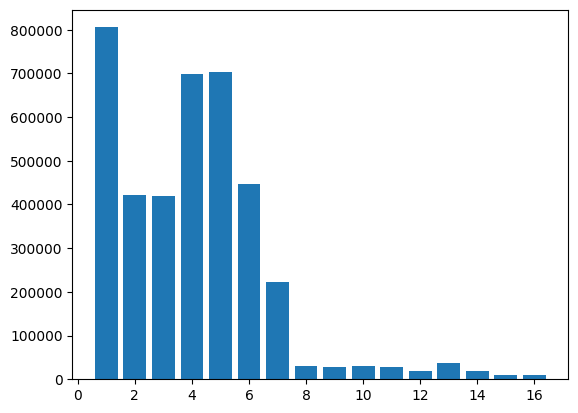

In [20]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

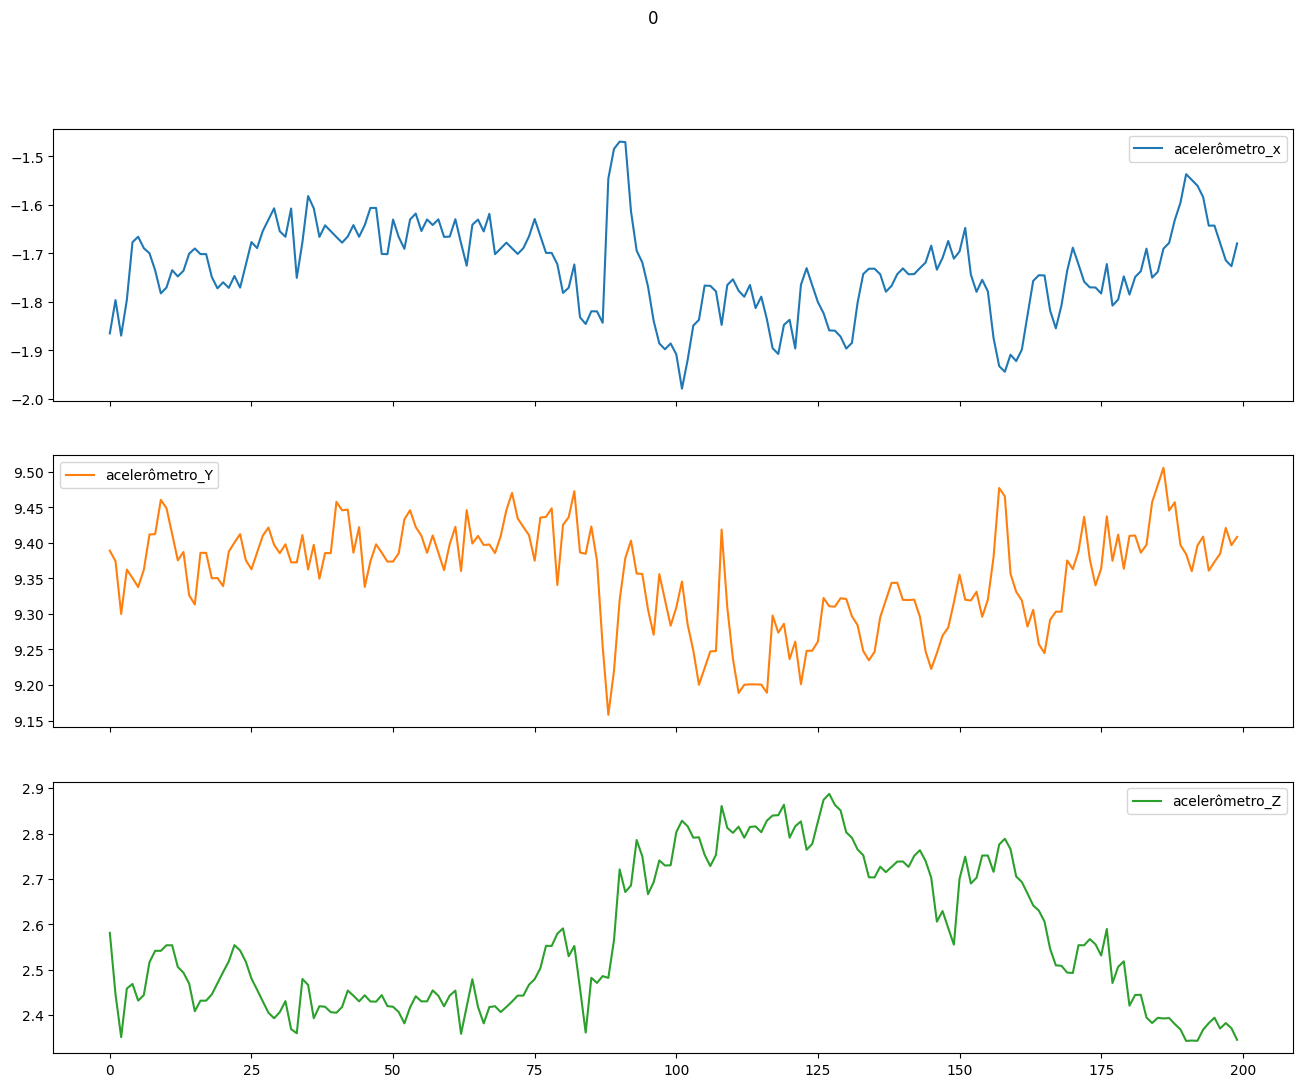

In [21]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 1 )&(data['pessoa_x']==0)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

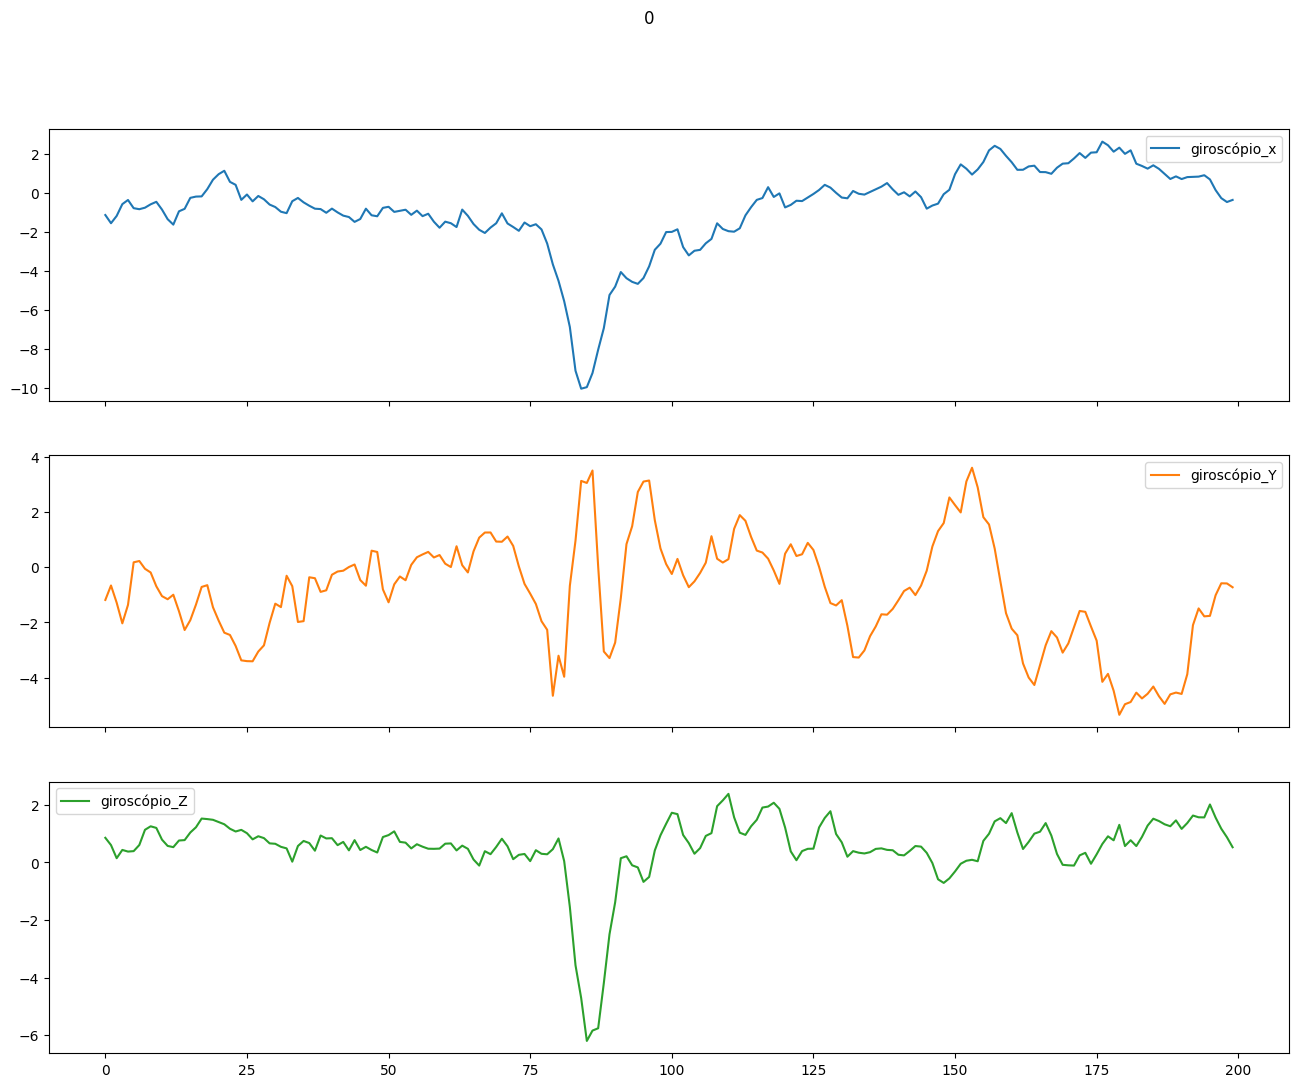

In [22]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 1 )&(data['pessoa_x']==0)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

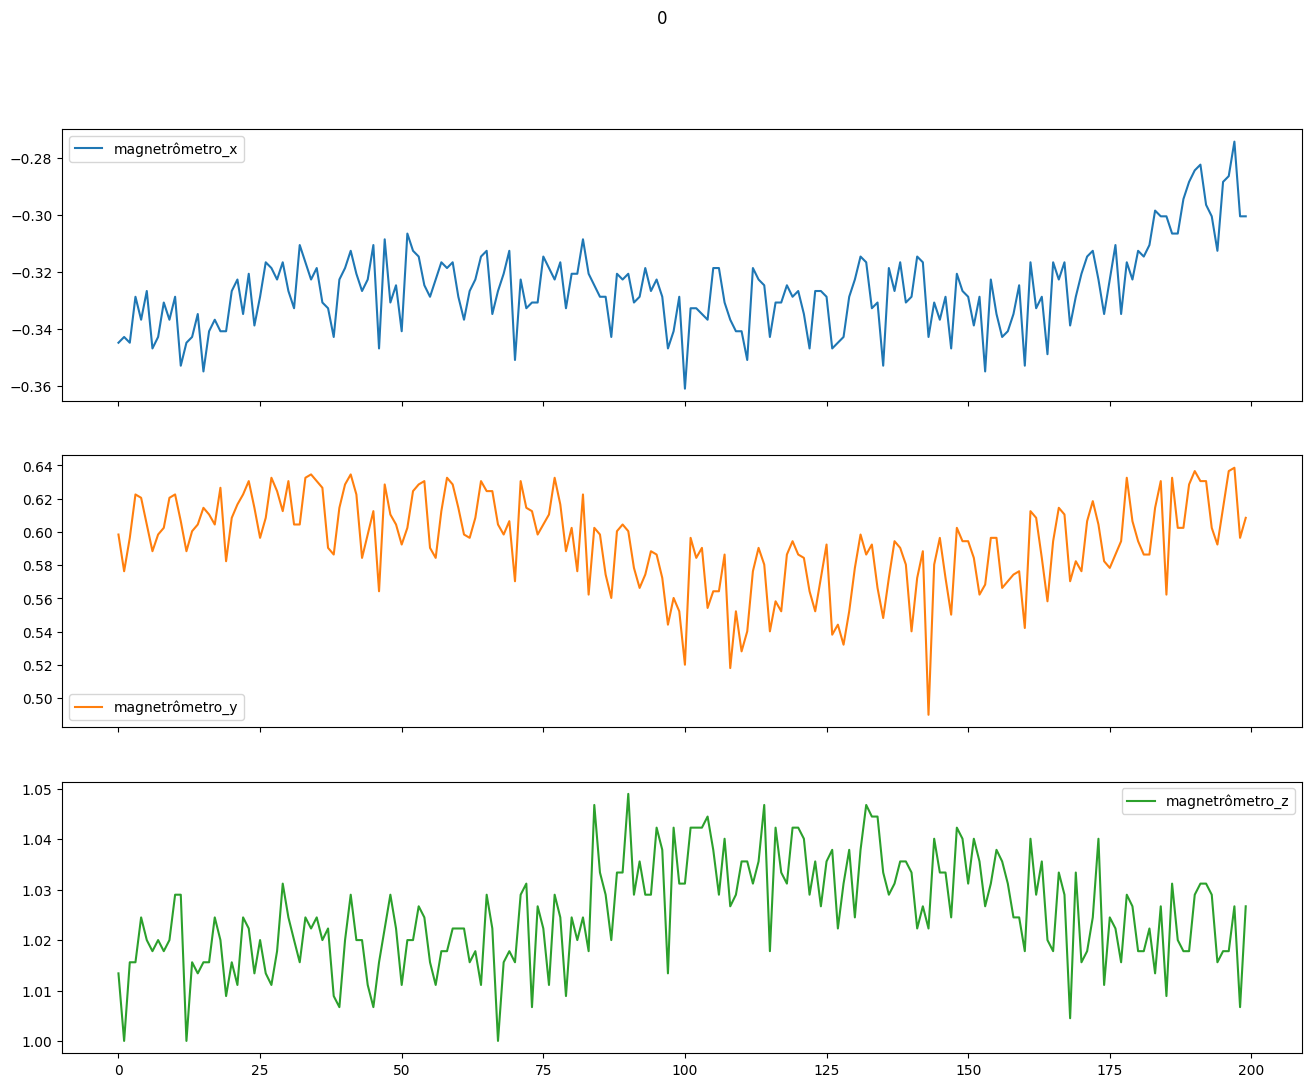

In [23]:
data[(data['atividade'] == 1 )&(data['pessoa_x']==0)][['magnetrômetro_x','magnetrômetro_y','magnetrômetro_z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

In [24]:
data.pessoa_x.unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14],
      dtype=int64)

In [25]:
data = data.reset_index(drop=True)

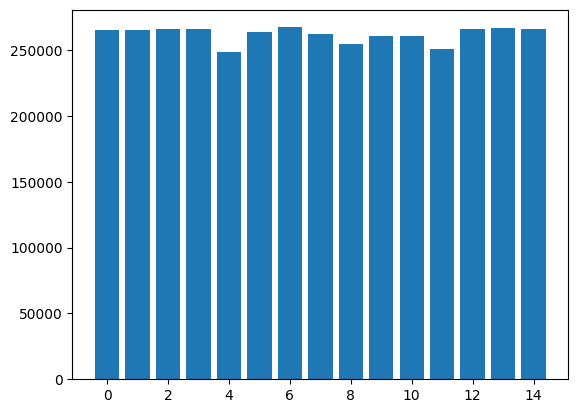

In [26]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [27]:
#selecting only activities 0 to 3
data = data[data["atividade"].isin([1,2,4,8,9,12])]

In [28]:
# Define the mapping dictionary
mapping_dict = {1:0,2:1,4:2,8:3,9:4,12:5}

In [29]:
data["atividade"] = data["atividade"].replace(to_replace=mapping_dict)

In [30]:
data.shape

(2004517, 13)

In [31]:
data['atividade'].value_counts()

atividade
0    805541
2    699414
1    421504
3     30976
4     28032
5     19050
Name: count, dtype: int64

In [32]:
data.head()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
0,0,1,-1.8650,9.3890,2.5812,-1.14180,-1.18560,0.84998,-0.34476,0.59839,1.0134,505.89,0
1,0,1,-1.7963,9.3742,2.4460,-1.56180,-0.66165,0.59730,-0.34274,0.57631,1.0000,525.42,0
2,0,1,-1.8696,9.3000,2.3514,-1.18770,-1.28410,0.14212,-0.34476,0.59639,1.0156,544.95,0
3,0,1,-1.7961,9.3624,2.4584,-0.58399,-2.03340,0.42912,-0.32863,0.62249,1.0156,564.48,0
4,0,1,-1.6768,9.3506,2.4685,-0.37050,-1.36470,0.37194,-0.33669,0.62048,1.0245,584.01,0


In [33]:
data.head()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
0,0,1,-1.8650,9.3890,2.5812,-1.14180,-1.18560,0.84998,-0.34476,0.59839,1.0134,505.89,0
1,0,1,-1.7963,9.3742,2.4460,-1.56180,-0.66165,0.59730,-0.34274,0.57631,1.0000,525.42,0
2,0,1,-1.8696,9.3000,2.3514,-1.18770,-1.28410,0.14212,-0.34476,0.59639,1.0156,544.95,0
3,0,1,-1.7961,9.3624,2.4584,-0.58399,-2.03340,0.42912,-0.32863,0.62249,1.0156,564.48,0
4,0,1,-1.6768,9.3506,2.4685,-0.37050,-1.36470,0.37194,-0.33669,0.62048,1.0245,584.01,0


In [34]:
data.shape

(2004517, 13)

In [35]:
grouped_data = data.groupby(['pessoa_x'])['atividade'].value_counts().unstack()

In [36]:
print(grouped_data)

atividade      0      1      2     3     4     5
pessoa_x                                        
0          54676  28800  45066  1920  1920  1270
1          52628  28288  48266  2176  1920  1270
2          55956  28416  46346  2048  2048  1270
3          54676  29056  46730  2176  1792  1270
4          51220  26240  44298  2304  1920  1270
5          52369  27904  47114  2176  1920  1270
6          58643  28800  47626  1920  1792  1270
7          50705  28928  46858  1920  1792  1270
8          49940  25600  46858  1792  1792  1270
9          51348  28032  47754  2432  1920  1270
10         57876  28416  46858  2176  1664  1270
11         53652  27136  43530  1920  1664  1270
12         53908  28544  48522  2048  1920  1270
13         54676  28416  46602  2304  1920  1270
14         53268  28928  46986  1664  2048  1270


In [37]:
nan_values = grouped_data[grouped_data.isnull().any(axis=1)].index

In [38]:
nan_values_array = nan_values.to_numpy()

In [39]:
print(nan_values)

Index([], dtype='int64', name='pessoa_x')


In [40]:
#data = data[~data['pessoa_x'].isin([1637,1640,1642])]

In [41]:
data['atividade'].value_counts()

atividade
0    805541
2    699414
1    421504
3     30976
4     28032
5     19050
Name: count, dtype: int64

In [42]:
import numpy as np

# Example array of shape (4027, 7) with categorical data in the second dimension
#array_data = np.random.randint(0, 7, (4027, 7))  # Replace with your actual data

def count_classes(array_data):
    # Flatten the array to count across all elements in the second dimension
    flattened_data = array_data.flatten()
    
    # Count unique values and their occurrences
    unique_classes, counts = np.unique(flattened_data, return_counts=True)
    
    # Create a dictionary to map classes to their counts
    class_counts = dict(zip(unique_classes, counts))
    
    return class_counts

# Get the counts for each class
#class_counts = count_classes(array_data)

# Print the counts



# **Models**

In [43]:
import numpy as np

# Example labels data array of shape (3152, 200, 1)
#labels_data = np.random.randint(0, 3, (3152, 200, 1))  # Replace with your actual labels array

def count_mixed_windows(labels_data):
    mixed_count = 0
    
    # Loop over each window
    for window in labels_data:
        # Flatten the window to a 1D array and find unique label values
        unique_labels = np.unique(window)
        
        # Check if there is more than one unique label in the window
        if len(unique_labels) > 1:
            mixed_count += 1
    
    return mixed_count

# Count the mixed windows
#mixed_window_count = count_mixed_windows(labels_data)
#print(f"Number of mixed windows: {mixed_window_count}")


In [44]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [45]:
import numpy as np

def ocurrence_unique_values(targets_test):

    # Example of 3D array with the format (256, 200, 1)
    #data = np.random.randint(0, 3, (256, 200, 1))

    # Reshape to (256, 200) to simplify the processing
    data_reshaped = targets_test.reshape(targets_test.shape[0], 200)

    # Get unique values per window (each window has 200 rows)
    # Since the second dimension always contains the same value, we can just select the first column for each window
    unique_values = data_reshaped[:, 0]

    # Count occurrences of each unique value (0, 1, 2)
    unique, counts = np.unique(unique_values, return_counts=True)

    # Create a dictionary to show the counts of 0, 1, and 2
    occurrences = dict(zip(unique, counts))
    return occurrences


In [46]:
import numpy as np

def count_unique_value_windows(data):
    # Reshape to (n, 200) by flattening the third dimension (since it's (426, 200, 1))
    data_reshaped = data.reshape(data.shape[0], 200)
    
    # Initialize a dictionary to count occurrences of windows with unique values
    occurrences = {0.: 0, 1.: 0, 2.: 0, 3.: 0, 4.: 0, 5.: 0, 6.: 0, 7.: 0, 8.: 0, 9.: 0, 
                   10.: 0, 11.: 0, 12.: 0, 13.: 0, 14.: 0, 15.: 0}

    # Iterate through each window
    for window in data_reshaped:
        # Check if the window contains only one unique value
        unique_vals = np.unique(window)
        if len(unique_vals) == 1:  # If only one unique value in the window
            occurrences[unique_vals[0]] += 1  # Increment the count for that value
    
    return occurrences

# Now the function works with the input of shape (426, 200, 1). 



In [47]:
def apply_segmentation_no_sliding_window(df_data):
# Define window size and step size
    window_size = 100
    step_size = 10

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using sliding window
    segments = np.zeros((n_windows, window_size, df_data.shape[1]-2),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        #populate the 3d array only if the 200 segment has the value in label
        label_consistency = (df_data[['atividade']][start_idx:end_idx].nunique()==1) 
        if label_consistency[0] == True:
            segments[i] = df_data[['pessoa_x','acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','magnetrômetro_x','magnetrômetro_y','magnetrômetro_z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [48]:
def apply_segmentation_with_sliding_window(df_data):
    #creating sliding window for train data
    import numpy as np

    window_size = 100
    step_size = 10

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-2),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        # Label consistency check
        label_consistency = (
            df_data[['atividade']][start_idx:end_idx].nunique()[0] == 1
            and first_row_value in [3, 4, 5]
        )
        if label_consistency:
            segments[i] = df_data[['pessoa_x','acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','magnetrômetro_x','magnetrômetro_y','magnetrômetro_z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [49]:
import numpy as np
from scipy.stats import mode  # Use mode to find the most common label

def apply_segmentation_with_sliding_window_transitions(df_data):
    window_size = 100
    step_size = 10

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-2), dtype=np.float32)
    targets = np.full((n_windows, window_size, 1), -1, dtype=np.int32)
    
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        
        # Fill segments with sensor data
        segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','magnetrômetro_x','magnetrômetro_y','magnetrômetro_z']][start_idx:end_idx]
        
        # Calculate the majority label for the window
        window_labels = df_data['atividade'][start_idx:end_idx]
        majority_label = mode(window_labels)[0][0]  # Gets the most frequent label

        # Assign the majority label to the entire window
        targets[i].fill(majority_label)

    return segments, targets


In [50]:
import numpy as np
def remove_useless_labels(labels_test,segments_test):

# Assuming array_3d is of shape (1239, 200, 6) and labels_1d is of shape (1239,)
    # Replace these with your actual arrays
    #array_3d = np.random.rand(1239, 200, 6)
    #labels_1d = np.random.randint(0, 9, size=(1239,))

    # Find the indices where labels are not 7 or 8
    valid_indices = np.where((labels_test != 7) & (labels_test != 8) & (labels_test != 9) 
                             & (labels_test != 10) & (labels_test != 11)
                             & (labels_test != 12) & (labels_test != 13)
                             & (labels_test != 14) & (labels_test != 15) )[0]

    # Filter both arrays
    filtered_labels_1d = labels_test[valid_indices]  # 1D array, indexed with 1 dimension
    filtered_array_3d = segments_test[valid_indices, :, :]  # 3D array, indexed with 3 dimensions

    return filtered_labels_1d, filtered_array_3d

    # Output the new shapes for verification
    #print("Filtered labels shape:", filtered_labels_1d.shape)
    #print("Filtered 3D array shape:", filtered_array_3d.shape)


In [51]:
print(data.pessoa_x.unique())

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]


In [52]:
data = data[['pessoa_x','acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','magnetrômetro_x','magnetrômetro_y','magnetrômetro_z','atividade']]


In [53]:
segments_data,targets_data = apply_segmentation_no_sliding_window(data)
print(segments_data.shape)
print(targets_data.shape)

(20045, 100, 9)
(20045, 100, 1)


In [54]:
segments_data,targets_data = delete_segments_not_fully_filled(segments_data,targets_data)
print(segments_data.shape)
print(targets_data.shape)

(19231, 100, 9)
(19231, 100, 1)


In [55]:
# Assuming your array is named 'data'
# Example: data = np.random.randint(0, 5, (3237, 200, 1))

# Reshape the array to 2D (ignoring the sequence dimension of 200)
flattened_labels = targets_data.reshape(-1)

# Use numpy's unique function to count occurrences of each label
unique_labels, counts = np.unique(flattened_labels, return_counts=True)

# Combine into a dictionary for better readability
label_counts = dict(zip(unique_labels, counts))

print("Label counts:", label_counts)

Label counts: {0: 775700, 1: 414300, 2: 684600, 3: 23200, 4: 21200, 5: 4100}


In [57]:
#count_unique = count_unique_value_windows(targets_data)

In [58]:
#print(count_unique)

In [ ]:
import numpy as np

def reorganize_labels(labels_test):

    # Example of a 1D array with length 1239 and values from 0 to 6
    #array_1d = np.random.randint(0, 7, size=1239)

    # Replace values 0 to 2 with 0
    labels_test = np.where(labels_test <= 3, 0, labels_test)

    # Replace values 3 to 6 with 1, 2, 3, and 4 respectively
    mapping = {4: 1, 5: 2, 6: 3}
    labels_test = np.vectorize(mapping.get)(labels_test, labels_test)  # Only changes values 3 to 6

    return labels_test


In [59]:
print(segments_data.shape)

(19231, 100, 9)


In [60]:
print(segments_data)

[[[-1.8650e+00  9.3890e+00  2.5812e+00 ... -3.4476e-01  5.9839e-01
    1.0134e+00]
  [-1.7963e+00  9.3742e+00  2.4460e+00 ... -3.4274e-01  5.7631e-01
    1.0000e+00]
  [-1.8696e+00  9.3000e+00  2.3514e+00 ... -3.4476e-01  5.9639e-01
    1.0156e+00]
  ...
  [-1.8857e+00  9.3560e+00  2.7408e+00 ... -3.4677e-01  5.4418e-01
    1.0134e+00]
  [-1.8978e+00  9.3197e+00  2.7296e+00 ... -3.4073e-01  5.6024e-01
    1.0423e+00]
  [-1.8859e+00  9.2835e+00  2.7301e+00 ... -3.2863e-01  5.5221e-01
    1.0312e+00]]

 [[-1.9082e+00  9.3091e+00  2.8032e+00 ... -3.6089e-01  5.2008e-01
    1.0312e+00]
  [-1.9791e+00  9.3457e+00  2.8283e+00 ... -3.3266e-01  5.9639e-01
    1.0423e+00]
  [-1.9199e+00  9.2852e+00  2.8161e+00 ... -3.3266e-01  5.8434e-01
    1.0423e+00]
  ...
  [-1.7143e+00  9.4211e+00  2.3824e+00 ... -2.7419e-01  6.3855e-01
    1.0267e+00]
  [-1.7264e+00  9.3968e+00  2.3710e+00 ... -3.0040e-01  5.9639e-01
    1.0067e+00]
  [-1.6793e+00  9.4084e+00  2.3454e+00 ... -3.0040e-01  6.0843e-01
    1.

In [ ]:
#segments_data, targets_data = split_and_shuffle_3d_arrays(segments_data, targets_data,range(1600, 1651) )

In [ ]:
# Assuming your array is named 'data'
# Example: data = np.random.randint(0, 5, (3237, 200, 1))

# Reshape the array to 2D (ignoring the sequence dimension of 200)
flattened_labels = targets_data.reshape(-1)

# Use numpy's unique function to count occurrences of each label
unique_labels, counts = np.unique(flattened_labels, return_counts=True)

# Combine into a dictionary for better readability
label_counts = dict(zip(unique_labels, counts))

print("Label counts:", label_counts)

In [ ]:
# Flatten the second dimension (3) into the first dimension
targets_data = targets_data.reshape(-1, 200, 1)

In [ ]:
print(targets_data.shape)

In [ ]:
# Assuming your array is named 'data'
# Example: data = np.random.randint(0, 5, (3237, 200, 1))

# Reshape the array to 2D (ignoring the sequence dimension of 200)
flattened_labels = targets_data.reshape(-1)

# Use numpy's unique function to count occurrences of each label
unique_labels, counts = np.unique(flattened_labels, return_counts=True)

# Combine into a dictionary for better readability
label_counts = dict(zip(unique_labels, counts))

print("Label counts:", label_counts)

In [ ]:
print(segments_data.shape)

In [ ]:
# Flatten the second dimension (3) into the first dimension
segments_data = segments_data.reshape(-1, 200, 7)

In [ ]:
print(segments_data.shape)

In [ ]:
import numpy as np

def category_count_categorical(labels_test_categorical):

    # Assuming your data is stored in a variable called `data`
    # Replace this with the actual data if it's available

    # Sum along the rows to get the count for each category
    category_counts_categorical = np.sum(labels_test_categorical, axis=0)

    # Print the counts
    print("Category counts:", category_counts_categorical)


In [ ]:
ocurrences = ocurrence_unique_values(targets_data)
print(ocurrences)

In [ ]:
#segments_test, targets_test = add_transition_windows(segments_test, targets_test)

In [ ]:
print(targets_data.shape)

In [ ]:
print(segments_data.shape)

In [ ]:
import numpy as np

# Assuming variable_data and label_data are your arrays
# variable_data has shape (2004, 200, 7) and label_data has shape (2004, 200, 1)

# Flatten the label array along the first dimension to make window indexing easier
labels_flattened = targets_data[:, 0, 0]  # Only take one value per window for class comparison

# Identify indices where the class label is 0 or 3
indices_class_0 = np.where(labels_flattened == 0)[0]
indices_class_3 = np.where(labels_flattened == 3)[0]

# Get the last 190 indices for class 0 and class 3
indices_to_remove = np.concatenate([indices_class_0[-190:], indices_class_3[-190:]])

# Remove the identified windows from both variable_data and label_data
segments_data = np.delete(segments_data, indices_to_remove, axis=0)
targets_data = np.delete(targets_data, indices_to_remove, axis=0)

# Output the shapes to verify the result
print("Original shape of variable_data:", targets_data.shape)
print("Original shape of label_data:", targets_data.shape)



In [ ]:
ocurrences = ocurrence_unique_values(targets_data)
print(ocurrences)

In [ ]:
print(targets_data)

In [ ]:
#mixed_window_count_data, targets_data = mark_mixed_windows(targets_data)

In [ ]:
print(targets_data.shape)

In [ ]:
print(segments_data.shape)

In [ ]:
count_unique_values = count_unique_value_windows(targets_data)

In [ ]:
print(count_unique_values)

In [ ]:
# Reshape the arrays to 2D, where each row corresponds to one time step across the entire dataset
segments_data = segments_data.reshape(-1, 7)  # Reshape to (324800, 7)
targets_data = targets_data.reshape(-1, 1)  # Reshape to (324800, 1)

# Concatenate horizontally
combined_data = np.hstack((segments_data, targets_data))

# Create a DataFrame
df_with_transitions = pd.DataFrame(combined_data, columns=['pessoa_x','acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade'])

# Check the shape to ensure it matches the expected length
print(df_with_transitions.shape)  # Should be (324800, 8)

# Display the first few rows
df_with_transitions.head()


In [ ]:
df_with_transitions.tail()

In [ ]:
df_with_transitions.atividade.value_counts()

In [ ]:
segments_data,targets_data = apply_segmentation_with_sliding_window_transitions(df_with_transitions)
print(segments_data.shape)
print(targets_data.shape)

In [ ]:
# Assuming your array is named 'data'
# Example: data = np.random.randint(0, 5, (3237, 200, 1))

# Reshape the array to 2D (ignoring the sequence dimension of 200)
flattened_labels = targets_data.reshape(-1)

# Use numpy's unique function to count occurrences of each label
unique_labels, counts = np.unique(flattened_labels, return_counts=True)

# Combine into a dictionary for better readability
label_counts = dict(zip(unique_labels, counts))

print("Label counts:", label_counts)

In [ ]:
print(count_unique_values)

In [ ]:
segments_data,targets_data = delete_segments_not_fully_filled(segments_data,targets_data)
print(segments_data.shape)
print(targets_data.shape)

In [ ]:
count_unique_values = count_unique_value_windows(targets_data)

In [ ]:
print(count_unique_values)

In [ ]:
count_unique_values = count_unique_value_windows(targets_data)

In [ ]:
print(count_unique_values)

In [ ]:
segments_data,targets_data = delete_segments_not_fully_filled(segments_data,targets_data)
print(segments_data.shape)
print(targets_data.shape)

In [ ]:
count_unique_values = count_unique_value_windows(targets_data)

In [ ]:
print(count_unique_values)

In [ ]:
""" # Print the number of mixed windows
print(f"Number of mixed windows: {mixed_window_count_data}")

# Example check of updated labels_data
print(targets_data) """

In [ ]:
# Count transition windows
transition_window_count_data = count_mixed_windows(targets_data)
print(f"Number of windows with transitions between labels: {transition_window_count_data}")

In [ ]:
targets_test = targets_data.reshape(targets_data.shape[0],200)

In [ ]:
print(targets_data.shape)

In [ ]:
print(targets_data)

In [ ]:
labels_data = targets_data[:,0]

In [ ]:
print(labels_data)

In [ ]:
print(labels_data.shape)

In [ ]:
print(segments_data.shape)

In [ ]:
#labels_data, segments_data = remove_useless_labels(labels_data,segments_data)

In [ ]:
print(segments_data.shape)

In [ ]:
print(labels_data.shape)

In [ ]:
print(segments_data.shape)

In [ ]:
labels_data = reorganize_labels(labels_data)

In [ ]:
print(labels_data.shape)

In [ ]:
print(labels_data)

In [ ]:
labels_data_categorical = to_categorical(labels_data,num_classes=4)

In [ ]:
print(labels_data_categorical)

In [ ]:
import numpy as np

# Function to count occurrences of each category
def count_categories(data):
    counts = {
        '[1, 0, 0, 0]': np.sum((data == [1., 0., 0., 0.]).all(axis=1)),
        '[0, 1, 0, 0]': np.sum((data == [0., 1., 0., 0.]).all(axis=1)),
        '[0, 0, 1, 0]': np.sum((data == [0., 0., 1., 0.]).all(axis=1)),
        '[0, 0, 0, 1]': np.sum((data == [0., 0., 0., 1.]).all(axis=1)),
    }
    return counts

# Count categories before removal
print("Category counts before removal:", count_categories(labels_data_categorical))

# Define the desired class count for the first category
desired_class_count = 2151

# Identify indices of the first class (1, 0, 0, 0) in labels_data_categorical
first_class_indices = np.where((labels_data_categorical == [1., 0., 0., 0.]).all(axis=1))[0]

# Randomly select indices to remove to balance the first class
indices_to_remove = np.random.choice(first_class_indices, size=(len(first_class_indices) - desired_class_count), replace=False)

# Remove the selected indices from both labels_data_categorical and segments_data
labels_data_categorical = np.delete(labels_data_categorical, indices_to_remove, axis=0)
segments_data = np.delete(segments_data, indices_to_remove, axis=0)

# Count categories after removal
print("Category counts after removal:", count_categories(labels_data_categorical))

# Print the shape of the new arrays to verify
print("New shape of labels_data_categorical:", labels_data_categorical.shape)
print("New shape of segments_data:", segments_data.shape)


In [ ]:
print(labels_data_categorical.shape)

In [ ]:
category_count_categorical(labels_data_categorical)

In [ ]:
print(segments_data.shape)

In [ ]:
print(segments_data)

In [ ]:
print(labels_data_categorical.shape)

In [ ]:
segments_data[:, :, 0] = segments_data[:, :, 0].astype(int)

In [ ]:
print(segments_data[:, :, 0])

In [ ]:
def split(segments_data, labels_data_categorical,interval):    
    import numpy as np

    # Assuming segments_data and labels_data_categorical are already defined as numpy arrays

    # Step 1: Convert the first position of all rows of the last dimension to INT format
    segments_data[:, :, 0] = segments_data[:, :, 0].astype(int)

    # Step 2: Zip segments_data and labels_data_categorical to maintain the rows of both arrays in the same index position
    zipped_data = list(zip(segments_data, labels_data_categorical))

    # Step 3: Remove all lines from zipped list where the segments of 200 points (window) have only the unique values {1600, 1601, 1602, 1603, 1604} in the first column
    filtered_data = [
        (segment, label) for segment, label in zipped_data
        if set(segment[:, 0]).issubset(interval)
    ]

    # Step 4: Unzip the new list into two final arrays: segments_test and targets_test
    if filtered_data:  # Check to avoid errors if the list is empty
        segments_test, targets_test = zip(*filtered_data)

        # Convert the results back to numpy arrays
        segments_test = np.array(segments_test)
        targets_test = np.array(targets_test)
        # Step 5: Remove the first position of the last dimension in segments_test to get shape (n, 200, 6)
        segments_test = segments_test[:, :, 1:]
    else:
        segments_test = np.array([])
        targets_test = np.array([])
        
    return segments_test,targets_test


    # segments_test and targets_test are now ready to use


In [ ]:
segments_test,targets_test = split(segments_data,labels_data_categorical,{1600, 1601, 1602, 1603, 1604})

In [ ]:
print(segments_test.shape)

In [ ]:
print(segments_test)

In [ ]:
print(targets_test.shape)

In [ ]:
segments_val,targets_val = split(segments_data,labels_data_categorical,{1605, 1606, 1607, 1608, 1609, 1610, 1611, 1612,1613})

In [ ]:
print(segments_val.shape)

In [ ]:
segments_train,targets_train = split(segments_data,labels_data_categorical,{1614,1615,1616,1617,1618,1619,1620,1621,1622,1623,1624,
                                                                            1625,1626,1627,1628,1629,1630,1631,1632,1633,1634,1635,1636,1637,1638,
                                                                            1639,1640,1641,1642,1643,1644,1645,1646,1647,1648,1649,1650,1651})

In [ ]:
print(segments_train.shape)

In [ ]:
print(segments_train)

In [ ]:
X_train = segments_train
y_train = targets_train
X_validation = segments_val
y_validation = targets_val

In [ ]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

In [ ]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [ ]:
X_train,y_train = shuffle_data(X_train,y_train)
X_validation,y_validation = shuffle_data(X_validation,y_validation)

In [ ]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

In [ ]:
print(y_train.shape)

In [ ]:
print(X_train.shape)

In [ ]:
#X_validation1, y_validation1 = add_transition_windows(X_validation, y_validation)

In [ ]:
#print(shuffled_labels)

In [ ]:
#from tensorflow.keras import regularizers

In [ ]:
''' def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu'))
  model.add(tf.keras.layers.BatchNormalization())  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model
 '''

In [ ]:
""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape
import keras.backend as K
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor(hp):
    inputs = Input(shape=(200, 6))
    lstm_out = LSTM(
        hp.Int("input_units_lstm1", min_value=32, max_value=512, step=32),
        kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
        recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
        return_sequences=True
    )(inputs)
    lstm_out = Dropout(hp.Float('dropout_rate', min_value=0.2, max_value=0.5, step=0.1))(lstm_out)
    
    # Attention mechanism
    attention = Dense(
        hp.Int("input_units_lstm1", min_value=32, max_value=512, step=32),
        activation='relu',
        kernel_regularizer=l2(hp.Float('l2_reg_attention', min_value=0.001, max_value=0.1, sampling='log'))
    )(lstm_out)
    attention = Permute([2, 1])(attention)
    attention = Activation('softmax')(attention)
    attention = Permute([2, 1])(attention)
    attention = Dropout(hp.Float('dropout_rate_attention', min_value=0.2, max_value=0.5, step=0.1))(attention)
    
    context_vector = Multiply()([lstm_out, attention])
    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)
    output = Dense(4, activation='softmax')(context_vector)
    
    model = Model(inputs=inputs, outputs=output)
    model.compile(
        loss='categorical_crossentropy',
        optimizer=tf.keras.optimizers.Adam(
            hp.Float('learning_rate', min_value=1e-4, max_value=1e-2, sampling='LOG', default=1e-3)
        ),
        metrics=['accuracy']
    )
    return model
 """

In [ ]:
from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape
import keras.backend as K

def lstm_attention_sensor(hp):
    inputs = Input(shape=(200,6))
    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),return_sequences=True)(inputs)
    
    # Attention mechanism
    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation='relu')(lstm_out)    
    attention = Permute([2, 1])(attention)
    attention = Activation('softmax')(attention)
    attention = Permute([2, 1])(attention)
    
    context_vector = Multiply()([lstm_out, attention])
    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    
    output = Dense(4, activation='softmax')(context_vector)
    
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
    return model


In [ ]:
tuner = RandomSearch(
    lstm_attention_sensor,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 5,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass")

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=7,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [ ]:
tuner.search(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=32, use_multiprocessing=True)

In [ ]:
tuner.results_summary()

In [ ]:
tuner.get_best_hyperparameters()[0].values

In [ ]:
best_model = tuner.get_best_models(num_models=1)[0]

In [ ]:
best_model.history

In [ ]:
best_model.summary()

In [ ]:
loss, accuracy = best_model.evaluate(X_validation, y_validation)

In [ ]:
predictions = best_model.predict(X_validation)

In [ ]:
print(y_validation)

In [ ]:
print(y_validation.shape)

In [ ]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [ ]:
print(y_validation_inverse)

In [ ]:
print(len(y_validation_inverse))

In [ ]:
print(predictions)

In [ ]:
classes_x=np.argmax(predictions,axis=1)

In [ ]:
print(classes_x)

In [ ]:
print(len(classes_x))

In [ ]:
print(classes_x.shape)

In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm = confusion_matrix(y_validation_inverse, classes_x)

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

In [ ]:
disp.plot()

In [ ]:
print(classification_report(y_validation_inverse, classes_x))

In [ ]:
print(segments_test)

In [ ]:
print(targets_test.shape)

In [ ]:
print(print(targets_test)
)

In [ ]:
loss_test, accuracy_test = best_model.evaluate(segments_test, targets_test)

In [ ]:
predictions_test = best_model.predict(segments_test)

In [ ]:
print(predictions_test)

In [ ]:
classes_x_test=np.argmax(predictions_test,axis=1)

In [ ]:
print(classes_x_test)

In [ ]:
labels_test_argmax = np.argmax(targets_test,axis=1)

In [ ]:
print(labels_test_argmax)

In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm_test = confusion_matrix(labels_test_argmax, classes_x_test)

In [ ]:
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
disp_test.plot()

In [ ]:
print(classification_report(labels_test_argmax, classes_x_test))

In [ ]:
best_model.save(WORKDIR+"/Model/best_models_saved_"+data_hora)